In [1]:
# chargement des librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import json

In [2]:
# chargement de quelques modules de machine learning
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score,recall_score
from sklearn.model_selection import cross_val_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import make_column_transformer, ColumnTransformer
from imblearn.over_sampling import SMOTE
from mlxtend.plotting import plot_confusion_matrix
from joblib import dump, load
import pickle
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.svm import SVR

In [3]:
# liste de toutes les variables explicatives
predictor_cols = ['location', 'mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine', 'windgustdir', 'windgustspeed', 
    'winddir9am', 'winddir3pm', 'windspeed9am', 'windspeed3pm', 'humidity9am', 'humidity3pm', 'pressure9am', 'pressure3pm', 
    'cloud9am', 'cloud3pm', 'temp9am', 'temp3pm', 'raintoday', 'year', 'month', 'day']

predictor_cols

['location',
 'mintemp',
 'maxtemp',
 'rainfall',
 'evaporation',
 'sunshine',
 'windgustdir',
 'windgustspeed',
 'winddir9am',
 'winddir3pm',
 'windspeed9am',
 'windspeed3pm',
 'humidity9am',
 'humidity3pm',
 'pressure9am',
 'pressure3pm',
 'cloud9am',
 'cloud3pm',
 'temp9am',
 'temp3pm',
 'raintoday',
 'year',
 'month',
 'day']

In [4]:
# nom de la variable réponse
response_col = 'raintomorrow'

response_col

'raintomorrow'

In [6]:
# function to read and return the datasets of features and target
def read_and_prepare_data(input_path):
    # read the dataset
    df = pd.read_csv(input_path)

    # remove missing values from the response variable (raintomorrow)
    df.dropna(subset=['raintomorrow'], inplace = True) 
    
    # extract dataset of the feature variables
    features = df.drop(['raintomorrow'], axis=1, inplace=False)
    
    # extract the datset of the target variable
    target = df['raintomorrow']
    
    # transform the target data to numerical data
    target.replace({'No':0, 'Yes': 1}, inplace = True)
    
    return features, target

In [7]:
# function to load the saved estimated machine learning pipeline
def load_saved_estimated_ml_model_pipeline(input_path):
    # load the saved model pipeline
    pickled_model = pickle.load(open(input_path, 'rb'))
    return pickled_model

In [8]:
# function to compute, plot and save the confusion matrix
def compute_and_save_confusion_matrix_plot(y_true, y_pred, ouput_path):
    confusion = confusion_matrix(y_true = y_true, y_pred = y_pred)
    plot_confusion_matrix(confusion, class_names=["No","Yes"], cmap='YlOrRd')
    plt.title('confusion matrix')
    plt.savefig(ouput_path)

In [9]:
# function to compute and save the classification report
def compute_and_save_classification_report(y_true, y_pred, ouput_path):
    report = classification_report(y_true = y_true, y_pred = y_pred, target_names = ["No","Yes"], output_dict = True)
    report_df = pd.DataFrame(report)
    report_df.to_csv(ouput_path,  sep=',', float_format='%.5f')
    print(report_df)

In [10]:
# execution du pipeline de prédiction et d'évaluation

In [12]:
# chemin du fichier csv à exploiter
input_test_data_path = "../../datasets/processed/latest/processed-weather-aus-latest.csv"

input_test_data_path

'../../datasets/processed/latest/processed-weather-aus-latest.csv'

In [23]:
# chemin de sauvegarde du meilleur modèle sauvegardé
#input_best_model_path = '../../models/best-model-pipe-2023-07-04-10-13-23.pkl'
input_best_model_path = '../../models/final-model-pipe-xgb-2023-07-15-11-45-34.pkl'
input_best_model_path

'../../models/final-model-pipe-xgb-2023-07-15-11-45-34.pkl'

In [14]:
# chemin de sauvegarde de la matrice de confusion
output_confusion_matrix_path = '../../models/confusion_matrix.png'

output_confusion_matrix_path

'../../models/confusion_matrix.png'

In [15]:
# chemin de sauvegarde du rapport de classification
output_classification_report_path = '../../models/classification_report.csv'
output_classification_report_path

output_classification_report_path_json = '../../models/classification_report.json'

In [16]:
# lecture des données à modéliser
X_test, y_test = read_and_prepare_data(input_path = input_test_data_path)

In [17]:
X_test.to_csv('../../models/test_data.csv')

In [24]:
# chargement et utilisation du modèle sauvegardé
pickled_best_model = load_saved_estimated_ml_model_pipeline(input_path = input_best_model_path)

pickled_best_model

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  Index(['mintemp', 'maxtemp', 'rainfall', 'evaporation', 'sunshine',
       'windgustspeed', 'windspeed9am', 'windspeed3pm', 'humidity9am',
       'humidity3pm', 'pressure9am', 'pressure3pm', 'cloud9a...
                               feature_types=None, gamma=None, gpu_id=None,
                               grow_policy=None, importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, n_estimators=100,
                               n_jobs=-1, num_parallel_tree=None,
                               predictor=None, random_state=None, ...))])

In [25]:
X_test.loc[[0,1,3,4,5,6,7]]

,location,mintemp,maxtemp,rainfall,evaporation,sunshine,windgustdir,windgustspeed,winddir9am,winddir3pm,...,pressure9am,pressure3pm,cloud9am,cloud3pm,temp9am,temp3pm,raintoday,year,month,day
0,Ballarat,5.1,11.5,2.2,NaN,NaN,S,33.0,SW,S,...,1024.4,1026.5,8.0,8.0,7.4,8.1,Yes,2023,7,1
1,Ballarat,6.2,9.6,0.6,NaN,NaN,SSE,35.0,SSE,S,...,1034.2,1033.3,8.0,8.0,7.0,9.2,No,2023,7,2
3,Ballarat,4.8,10.4,0.8,NaN,NaN,N,43.0,NNE,NNE,...,1017.4,1012.2,8.0,8.0,8.3,9.3,No,2023,7,4
4,Ballarat,5.4,11.6,4.4,NaN,NaN,N,39.0,N,NNW,...,1012.7,1011.4,8.0,1.0,7.3,10.7,Yes,2023,7,5
5,Ballarat,6.3,11.5,0.2,NaN,NaN,N,59.0,N,N,...,1010.1,1005.6,8.0,8.0,7.1,9.9,No,2023,7,6
6,Ballarat,6.0,11.1,2.0,NaN,NaN,N,61.0,WNW,NNW,...,1011.1,1009.9,8.0,7.0,7.5,10.3,Yes,2023,7,7
7,Ballarat,6.6,10.5,3.8,NaN,NaN,W,72.0,NW,WNW,...,1005.4,1007.7,6.0,4.0,7.4,9.0,Yes,2023,7,8


In [26]:
# utilisation du modèle chargé
predictions = pickled_best_model.predict(X_test)

predictions

array([1, 0, 0, ..., 1, 1, 0])

In [27]:
report = classification_report(y_true = y_test, y_pred = predictions, target_names = ["No","Yes"], output_dict = True)
report

{'No': {'precision': 0.9160125588697017,
  'recall': 0.7271028037383177,
  'f1-score': 0.8106981590830149,
  'support': 1605},
 'Yes': {'precision': 0.5295381310418904,
  'recall': 0.8216666666666667,
  'f1-score': 0.6440235140431091,
  'support': 600},
 'accuracy': 0.7528344671201814,
 'macro avg': {'precision': 0.7227753449557961,
  'recall': 0.7743847352024922,
  'f1-score': 0.7273608365630619,
  'support': 2205},
 'weighted avg': {'precision': 0.8108494492566918,
  'recall': 0.7528344671201814,
  'f1-score': 0.7653445141741969,
  'support': 2205}}

In [28]:
# Serializing json
json_object = json.dumps(report, indent=4)
 
# Writing to sample.json
with open(output_classification_report_path_json, "w") as outfile:
    outfile.write(json_object)


In [29]:
# save the classification report
compute_and_save_classification_report(y_true = y_test, y_pred = predictions, ouput_path = output_classification_report_path)

                    No         Yes  accuracy    macro avg  weighted avg
precision     0.916013    0.529538  0.752834     0.722775      0.810849
recall        0.727103    0.821667  0.752834     0.774385      0.752834
f1-score      0.810698    0.644024  0.752834     0.727361      0.765345
support    1605.000000  600.000000  0.752834  2205.000000   2205.000000


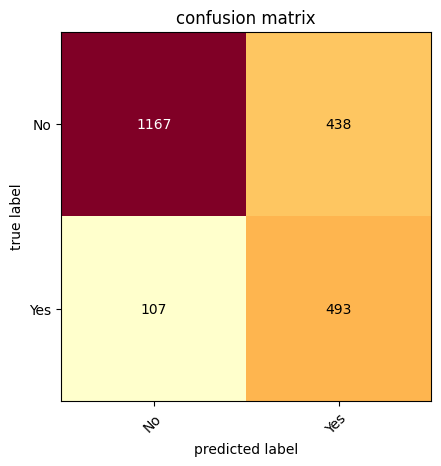

In [30]:
# save the confusion matrix
compute_and_save_confusion_matrix_plot(y_true = y_test, y_pred = predictions, ouput_path = output_confusion_matrix_path)